# Bước 5. Opportunity gap và nguyên nhân

Notebook này trả lời: mỗi shop còn tăng thêm được bao nhiêu contract mỗi tháng nếu công ty can thiệp hợp lý, phần tăng đó đến từ đâu, và nên làm gì với từng shop.

**Opportunity gap** (phần cơ hội, tức phần shop tăng thêm được nhờ can thiệp) = Attainable Potential (Bước 3) − BAU (Bước 2). Gap được tính bằng cả số contract và funded volume (tổng tiền cho khách vay).

**Đầu vào:**
- Bước 1: `Bước 1/shop_current.csv` (Current Actual và KPI quý 3/2026), `Bước 1/shop_month.csv` (KPI theo tháng), `Bước 1/shop_goods_mix.csv` (nhóm hàng của contract).
- Bước 2: `Bước 2/shop_bau.csv` và `Bước 2/bau_params.json` (BAU 10/2026–03/2027 và các tham số).
- Bước 3: `output/shop_attainable.csv` (benchmark và KPI sau khi nâng).
- Bước 4: các file trong `Bước 4/task4_output/csv/` (dân số tuổi lao động theo tỉnh, contract ghi công theo shop × tháng, trần của shop).
- `clean_data/salesroom.csv`, `clean_data/seller.csv` (loại đối tác của shop).
- `r3_tiem_nang.py`: các hàm viết lại phép tính của Bước 3 và Bước 4, dùng chung cho Bước 5, 6, 7.

**Các mục:** 5.1 ghép 4 con số của mỗi shop → 5.2 kiểm tra thứ tự 4 con số → 5.3 tính trần thị trường trên cùng quý với Current Actual → 5.4 opportunity gap → 5.5 gap đến từ KPI nào → 5.6 sáu nhóm nguyên nhân → 5.7 nguyên nhân chính và hành động cho từng shop → 5.8 hai shop thật cùng doanh số nhưng gap khác nhau → 5.9 ghi file.

**File kết quả:** `Bước 5/shop_gap.csv` (mỗi dòng một shop: 4 con số, gap theo contract và tiền, phần gap theo từng KPI, nguyên nhân chính, hành động), dùng ở Bước 6; `Bước 5/province_ceiling_q3.csv` (trần của 34 tỉnh).

## 5.1. Ghép 4 con số của mỗi shop

Ô dưới đây đọc kết quả của Bước 1 đến Bước 4 và đếm số shop của từng nguồn khớp với danh sách shop được đánh giá ở Bước 1 (shop Active có mặt bằng, không tính shop online).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'Bước 1').exists())   # thư mục gốc của bài
sys.path.insert(0, str(ROOT))
from r3_tiem_nang import *
warnings.filterwarnings('ignore', category=RuntimeWarning)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 120)
def _fmt(x):
    if x != x: return 'NaN'
    if x == int(x): return f'{x:,.0f}'
    return f'{x:,.1f}' if abs(x) >= 100 else f'{x:,.3f}'
pd.set_option('display.float_format', _fmt)

# Kiểu biểu đồ dùng chung với các bước trước: một màu chính, không có lưới.
BLUE, ORANGE, INK, MUTED, GREY = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#b9b8b3'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'axes.edgecolor': '#bdbcb8',
                     'axes.grid': False, 'grid.color': '#ecebe8', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
                     'lines.linewidth': 2})

cur = pd.read_csv(ROOT / 'Bước 1' / 'shop_current.csv', encoding='utf-8-sig')
mix = pd.read_csv(ROOT / 'Bước 1' / 'shop_goods_mix.csv', encoding='utf-8-sig')
bau = pd.read_csv(ROOT / 'Bước 2' / 'shop_bau.csv', encoding='utf-8-sig', dtype={'shop_id': str})
ap3 = pd.read_csv(ROOT / 'output' / 'shop_attainable.csv', encoding='utf-8-sig')
T4 = ROOT / 'Bước 4' / 'task4_output' / 'csv'
s1, s2, s3 = (pd.read_csv(T4 / f, encoding='utf-8-sig') for f in ['s1_external_checked.csv', 's2_shop_master.csv', 's3_shop_month.csv'])
s7 = pd.read_csv(T4 / 's7_shop_ceiling.csv', encoding='utf-8-sig')
sr = pd.read_csv(ROOT / 'clean_data' / 'salesroom.csv', encoding='utf-8-sig')
seller = pd.read_csv(ROOT / 'clean_data' / 'seller.csv', encoding='utf-8-sig')


# Biểu đồ được lưu thành ảnh PNG trong thư mục Bước 5/hinh.
HINH = ROOT / 'Bước 5' / 'hinh'
HINH.mkdir(exist_ok=True)
def luu_hinh(fig, ten):
    fig.savefig(HINH / f'{ten}.png', dpi=200, bbox_inches='tight')

d = cur[(cur.salesroom_status == 'Active') & (cur.shop_online == 0)].copy()
bau = bau[bau.shop_id != 'VIRTUAL'].assign(skp_salesroom=lambda b: b.shop_id.astype(int))
pd.DataFrame({'so_dong': [len(d), len(bau), len(ap3), len(s7)],
              'khop_voi_buoc_1': [len(d), bau.skp_salesroom.isin(d.skp_salesroom).sum(), ap3.skp_salesroom.isin(d.skp_salesroom).sum(),
                                  s7['shop'].isin(d.skp_salesroom).sum()]},
             index=['Bước 1: shop Active có mặt bằng', 'Bước 2: BAU', 'Bước 3: Attainable Potential', 'Bước 4: trần của shop'])


,so_dong,khop_voi_buoc_1
Bước 1: shop Active có mặt bằng,11752,11752
Bước 2: BAU,11752,11752
Bước 3: Attainable Potential,11752,11752
Bước 4: trần của shop,11752,11752


Cả bốn nguồn có đúng 11.752 shop và khớp hoàn toàn với nhau.

Bước 2 tính BAU từ bảng KPI theo tháng mà Bước 1 tạo riêng cho Bước 2 (Bước 1, mục 1.9), nên trước khi lấy Attainable Potential trừ BAU cần chắc hai bước đo doanh số theo cùng một cách. Ô dưới đây so Current Actual của Bước 1 với Current Actual mà Bước 2 đọc lại, và in BAU của Bước 2 theo hai phần: bán tại shop và cross-sell ký ở nơi khác.

In [2]:
x = d[['skp_salesroom', 'ca_hd_truc_tiep', 'ca_xsell', 'ca_hd_tong']].merge(
    bau[['skp_salesroom', 'ca_signed_contracts', 'ca_cross_sell_booked_elsewhere_or_online', 'bau_contracts',
         'bau_xsell_elsewhere_contracts', 'bau_total_contribution_contracts']], on='skp_salesroom')
lech = (x.ca_hd_truc_tiep - x.ca_signed_contracts).abs()
print(f'Shop có Current Actual bán trực tiếp khác nhau giữa Bước 1 và Bước 2: {int((lech > 1e-9).sum())}, lệch lớn nhất {lech.max():.2f} contract/tháng')
pd.DataFrame({'bán tại shop': [x.ca_hd_truc_tiep.sum(), x.ca_signed_contracts.sum(), x.bau_contracts.sum()],
              'cross-sell ký ở nơi khác': [x.ca_xsell.sum(), x.ca_cross_sell_booked_elsewhere_or_online.sum(), x.bau_xsell_elsewhere_contracts.sum()],
              'tổng': [x.ca_hd_tong.sum(), x.ca_signed_contracts.sum() + x.ca_cross_sell_booked_elsewhere_or_online.sum(),
                       x.bau_total_contribution_contracts.sum()]},
             index=['Current Actual (Bước 1)', 'Current Actual (Bước 2 đọc lại)', 'BAU (Bước 2)'])

Shop có Current Actual bán trực tiếp khác nhau giữa Bước 1 và Bước 2: 0, lệch lớn nhất 0.00 contract/tháng


,bán tại shop,cross-sell ký ở nơi khác,tổng
Current Actual (Bước 1),"37,664","1,786","39,450"
Current Actual (Bước 2 đọc lại),"37,664","1,786","39,450"
BAU (Bước 2),"37,733.6","1,538.0","39,271.6"


- Current Actual mà Bước 2 đọc lại trùng hoàn toàn với Bước 1 ở mọi shop: bán tại shop 37.664, cross-sell ký ở nơi khác 1.786 contract mỗi tháng.
- Vì vậy BAU được lấy là cột `bau_total_contribution_contracts` của Bước 2, bằng BAU bán tại shop cộng BAU cross-sell ký ở nơi khác: 39.271,6 contract mỗi tháng. Cách đo này giống Current Actual của Bước 1 (bán trực tiếp cộng cross-sell), nên phép trừ có nghĩa.

Attainable Potential lấy từ Bước 3 là phần bán trực tiếp (`ap_truc_tiep`) cộng phần cross-sell (`ap_xsell`), rồi so lại với BAU của Bước 2: shop nào có BAU cao hơn thì Attainable Potential bằng BAU, vì can thiệp không thể cho kết quả thấp hơn khi để yên.

## 5.2. Kiểm tra thứ tự 4 con số

Thứ tự hợp lý của 4 con số là: Current Actual và BAU thấp nhất, rồi đến Attainable Potential, cao nhất là Addressable Market Ceiling (trần thị trường). Ô dưới đây ghép trần của từng shop từ Bước 4 (cột `addressable_market_ceiling_pm`, contract mỗi tháng) và đếm số shop sai thứ tự.

In [3]:
o = d[['skp_salesroom', 'ca_hd_tong']].merge(bau[['skp_salesroom', 'bau_total_contribution_contracts']], on='skp_salesroom') \
     .merge(ap3[['skp_salesroom', 'ap_truc_tiep', 'ap_xsell']], on='skp_salesroom') \
     .merge(s7.rename(columns={'shop': 'skp_salesroom'})[['skp_salesroom', 'addressable_market_ceiling_pm', 'current_pm']], on='skp_salesroom')
o['bau'] = o.bau_total_contribution_contracts
o['ap_tho'] = np.maximum(o.ap_truc_tiep + o.ap_xsell, o.bau)
o['tran'] = o.addressable_market_ceiling_pm
pd.DataFrame({'so_shop': [int((o.tran < o.ca_hd_tong - 1e-9).sum()), int((o.tran < o.bau - 1e-9).sum()), int((o.ap_tho > o.tran + 1e-9).sum())]},
             index=['trần < Current Actual', 'trần < BAU', 'Attainable Potential > trần (sẽ bị cắt)'])

,so_shop
trần < Current Actual,1435
trần < BAU,1144
Attainable Potential > trần (sẽ bị cắt),4389


Có 1.435 shop có trần thấp hơn mức đang bán, 1.144 shop có trần thấp hơn BAU, và 4.389 shop sẽ bị trần cắt Attainable Potential. Trần là mức lý thuyết cao nhất, nên không thể thấp hơn số contract shop đang thực sự ký. Hai nguyên nhân được kiểm tra lần lượt dưới đây.

Nguyên nhân thứ nhất: trần ở Bước 4 được tính trên trung bình 01–09/2026, còn Current Actual là trung bình 07–09/2026. Ô dưới đây in số contract ghi công cho shop vật lý theo từng tháng của năm 2026, lấy từ chính file của Bước 4.

In [4]:
thang_q = s3.groupby('month').contracts.sum().loc['2026-01':'2026-09']
print('Số contract ghi công cho shop vật lý mỗi tháng (Bước 4, file s3_shop_month):')
print(thang_q.round(0).to_string())
print(f"Trung bình 01–09/2026: {thang_q.mean():,.0f}; trung bình 07–09/2026: {thang_q.loc['2026-07':].mean():,.0f} contract/tháng")

Số contract ghi công cho shop vật lý mỗi tháng (Bước 4, file s3_shop_month):
month
2026-01   25,601
2026-02   26,100
2026-03   30,149
2026-04   30,324
2026-05   32,404
2026-06   33,231
2026-07   37,230
2026-08   43,141
2026-09   42,752
Trung bình 01–09/2026: 33,437; trung bình 07–09/2026: 41,041 contract/tháng


Số contract tăng đều từ 25.601 (01/2026) lên 42.752 (09/2026), vì mạng lưới mở thêm shop liên tục. Trung bình 9 tháng chỉ là 33.437 contract mỗi tháng, thấp hơn 41.041 của quý 3 khoảng 19% (33.437 / 41.041 ≈ 0,81). Penetration (số contract trên 1.000 người tuổi lao động) đo trên 9 tháng vì vậy thấp hơn mức mạng lưới đang đạt, và trần tính từ đó bị kéo xuống.

Nguyên nhân thứ hai: khi chia trần tỉnh cho shop, mọi shop cùng cỡ trong một tỉnh nhận phần trần bằng nhau. Ô dưới đây lấy ví dụ TP. Hồ Chí Minh: phần trần mỗi tháng của một shop theo từng cỡ, so với mức đang bán của các shop cùng cỡ. Dòng cuối in một kết quả của Bước 2 dùng cho lựa chọn ở dưới.

In [5]:
v = s7.merge(d[['skp_salesroom', 'ca_hd_tong']], left_on='shop', right_on='skp_salesroom')
hcm = v[v.province == 'TP. Hồ Chí Minh']
display(hcm.groupby('category').agg(so_shop=('shop', 'size'), tran_chia_theo_co_shop=('ceiling_alloc', lambda s: s.iloc[0] / 12),
        ca_trung_vi=('ca_hd_tong', 'median'), ca_cao_nhat=('ca_hd_tong', 'max'),
        so_shop_ca_vuot_phan_chia=('ca_hd_tong', lambda s: int((s > hcm.loc[s.index, 'ceiling_alloc'] / 12).sum()))))
print(f"Toàn quốc: {int(s7.current_exceeds_alloc.sum()):,} trên {len(s7):,} shop có mức đang bán (theo cách đo của Bước 4) cao hơn phần trần được chia")
bp = json.load(open(ROOT / 'Bước 2' / 'bau_params.json', encoding='utf-8'))
print(f"Bước 2: tương quan của biến động theo tháng giữa 2025 và 2026 = {bp['season_corr_2025_2026']:+.2f}")

,so_shop,tran_chia_theo_co_shop,ca_trung_vi,ca_cao_nhat,so_shop_ca_vuot_phan_chia
category,,,,,
Big,329,5.305,1.333,208,96
Medium,982,3.676,1,110,253
Small,824,2.987,0.667,106.3,208


Toàn quốc: 2,537 trên 11,752 shop có mức đang bán (theo cách đo của Bước 4) cao hơn phần trần được chia
Bước 2: tương quan của biến động theo tháng giữa 2025 và 2026 = -0.15


- Ở TP. Hồ Chí Minh, mỗi shop Small được chia khoảng 3 contract mỗi tháng (2,987), nhưng shop Small bán nhiều nhất đang ký 106,3 contract mỗi tháng; 208 shop Small đang bán nhiều hơn phần được chia, cùng với 253 shop Medium và 96 shop Big.
- Toàn quốc có 2.537 shop đang bán nhiều hơn phần trần được chia. Bước 4 nâng trần của các shop này lên bằng mức đang bán, nên các shop đó không còn chỗ tăng nào, dù KPI của shop có thể kém xa shop cùng loại.

Có hai cách xử lý:
- **Cách 1: giữ nguyên trần của shop như Bước 4.** Ưu điểm: không thay đổi con số đã có. Nhược điểm: 1.435 shop có trần thấp hơn mức đang bán; shop đang bán nhiều bị chặn ở mức hiện tại chỉ vì cỡ shop, không phải vì thị trường hết khách.
- **Cách 2: giữ nguyên công thức trần tỉnh của Bước 4, nhưng đo trên cùng quý 3/2026 như Current Actual, rồi chia trần tỉnh cho shop theo mức thực tế của từng shop.** Công thức trần tỉnh vẫn là: penetration chuẩn bằng trung vị penetration của nhóm 1/4 số tỉnh cao nhất, nhân với dân số tuổi lao động của tỉnh. Mức thực tế của shop là số lớn hơn giữa Attainable Potential (trước khi áp trần) và Current Actual. Ưu điểm: trần và Current Actual đo cùng một giai đoạn; tổng trần của các shop trong tỉnh bằng trần của tỉnh; shop bán nhiều được chia nhiều. Nhược điểm: trần của shop phụ thuộc vào Attainable Potential của Bước 3; nếu quý 3 là mùa cao điểm thì trần bị đẩy lên, nhưng Bước 2 cho thấy biến động theo tháng không lặp lại giữa 2025 và 2026 (tương quan −0,15, dòng cuối ở trên), nên ảnh hưởng này nhỏ.

Bài chọn cách 2. Trần của shop không thấp hơn số lớn hơn giữa Current Actual và BAU, giống cách Bước 4 không để trần thấp hơn mức đang bán.

## 5.3. Trần thị trường tính trên quý 3/2026

Hàm `tran_tinh` trong `r3_tiem_nang.py` viết lại công thức trần tỉnh của Bước 4. Ô dưới đây chạy hàm này hai lần: với cửa sổ 01–09/2026 để kiểm tra hàm cho đúng số của Bước 4, rồi với cửa sổ 07–09/2026. Bảng in 12 tỉnh có penetration cao nhất: số contract đang bán mỗi tháng (`q_thang`), trần (`tran_thang`) và phần còn trống (`con_trong`).

In [6]:
kt, pi_kt = tran_tinh(s3, s2, s1, [f'2026-{m:02d}' for m in range(1, 10)])
print(f'Làm lại Bước 4 với cửa sổ 01–09/2026: π* = {pi_kt:.3f}, trần toàn quốc = {kt.tran_nam.sum():,.0f} contract/năm')
tran, pi_sao = tran_tinh(s3, s2, s1, ['2026-07', '2026-08', '2026-09'])
print(f'Cửa sổ 07–09/2026: π* = {pi_sao:.3f}, trần toàn quốc = {tran.tran_thang.sum():,.0f} contract/tháng, '
      f'đang bán {tran.q_thang.sum():,.0f} contract/tháng (gấp {tran.tran_thang.sum() / tran.q_thang.sum():.2f} lần)')
tran.assign(con_trong=lambda t: t.tran_thang - t.q_thang).sort_values('penetration', ascending=False)[
    ['province', 'penetration', 'q_thang', 'tran_thang', 'con_trong']].head(12)

Làm lại Bước 4 với cửa sổ 01–09/2026: π* = 10.550, trần toàn quốc = 586,892 contract/năm
Cửa sổ 07–09/2026: π* = 13.307, trần toàn quốc = 61,083 contract/tháng, đang bán 41,041 contract/tháng (gấp 1.49 lần)


,province,penetration,q_thang,tran_thang,con_trong
29,Đồng Nai,15.777,"3,299","3,299",0
32,TP. Hồ Chí Minh,14.948,"9,569.3","9,569.3",0
16,Khánh Hoà,14.480,"1,264","1,264",0
15,TP. Cần Thơ,13.438,"1,877.7","1,877.7",0
20,TP. Huế,13.307,697,697,0
19,An Giang,12.975,"2,016.3","2,068.0",51.700
33,TP. Hà Nội,10.965,"3,891.7","4,723.2",831.5
24,TP. Đà Nẵng,10.619,"1,355.3","1,698.5",343.1
13,Cà Mau,8.901,832.7,"1,244.9",412.2
11,Lâm Đồng,7.983,"1,272.7","2,121.4",848.7


- Với cửa sổ 01–09/2026, hàm cho đúng penetration chuẩn π* = 10,550 và trần toàn quốc 586.892 contract mỗi năm như Bước 4.
- Với quý 3/2026, π* tăng lên 13,307 contract mỗi năm trên 1.000 người tuổi lao động. Trần toàn quốc là 61.083 contract mỗi tháng, gấp 1,49 lần mức đang bán, gần với mức 1,46 lần của Bước 4.
- 5 tỉnh có penetration từ mức chuẩn trở lên (Đồng Nai, TP. Hồ Chí Minh, Khánh Hòa, TP. Cần Thơ, TP. Huế) có trần bằng đúng mức đang bán, không còn chỗ trống. Đây là các tỉnh công ty đã bán nhiều nhất so với dân số. An Giang gần chạm trần, chỉ còn 51,7 contract mỗi tháng.

Ô dưới đây làm lại Attainable Potential của Bước 3 bằng hàm `attainable` (để có đủ các cột benchmark và KPI sau khi nâng) và kiểm tra hàm cho đúng số của Bước 3. Sau đó hàm `ghep_4_so`:
- chia trần tỉnh cho shop theo mức thực tế của shop; trần của shop không thấp hơn Current Actual và BAU;
- tính Attainable Potential = số nhỏ hơn giữa Attainable Potential trước khi áp trần (đã so với BAU) và trần của shop;
- tính opportunity gap = Attainable Potential − BAU.

Cuối ô đếm lại số shop sai thứ tự và cộng 4 con số của toàn mạng lưới.

In [7]:
k = kpi_shop(cur[['skp_salesroom'] + G + ['salesroom_status', 'shop_online', 'shop_moi', 'thang_bat_dau', 'so_thang']],
             pd.read_csv(ROOT / 'Bước 1' / 'shop_month.csv', encoding='utf-8-sig'), '2026-07-01', '2026-09-01')
x = attainable(k[(k.salesroom_status == 'Active') & (k.shop_online == 0)])
kiem = x.merge(ap3[['skp_salesroom', 'ap_truc_tiep', 'ap_xsell']], on='skp_salesroom', suffixes=('', '_b3'))
print('Lệch lớn nhất so với file Bước 3: bán trực tiếp', f"{(kiem.ap_truc_tiep - kiem.ap_truc_tiep_b3).abs().max():.1e},",
      'cross-sell', f"{(kiem.ap_xsell - kiem.ap_xsell_b3).abs().max():.1e}")
s = ghep_4_so(x, bau.set_index('skp_salesroom').bau_total_contribution_contracts, s2.set_index('shop').pkey, tran)
print('Shop sai thứ tự (BAU > AP, AP > trần, hoặc Current Actual > trần):',
      int(((s.bau > s.ap + 1e-9) | (s.ap > s.tran_shop + 1e-9) | (s.ca_hd_tong > s.tran_shop + 1e-9)).sum()))
pd.DataFrame({'contract_moi_thang': [s.ca_hd_tong.sum(), s.bau.sum(), s.ap.sum(), s.tran_shop.sum()]},
             index=['Current Actual', 'BAU', 'Attainable Potential', 'Addressable Market Ceiling'])

Lệch lớn nhất so với file Bước 3: bán trực tiếp 5.7e-14, cross-sell 3.3e-14
Shop sai thứ tự (BAU > AP, AP > trần, hoặc Current Actual > trần): 0


,contract_moi_thang
Current Actual,"39,450"
BAU,"39,271.6"
Attainable Potential,"55,595.3"
Addressable Market Ceiling,"65,958.6"


- Hàm cho đúng Attainable Potential của Bước 3 (lệch lớn nhất cỡ 10⁻¹³, chỉ là sai số làm tròn của máy tính).
- Không còn shop nào sai thứ tự.
- Toàn mạng lưới: Current Actual 39.450, BAU 39.271,6, Attainable Potential 55.595,3 và Addressable Market Ceiling 65.958,6 contract mỗi tháng. Trần của các shop cộng lại (65.959) cao hơn trần của các tỉnh cộng lại (61.083), vì ở các tỉnh đã chạm trần, trần của shop được nâng lên bằng Current Actual hoặc BAU của shop.

Ô dưới đây cộng phần Attainable Potential bị trần cắt theo tỉnh.

In [8]:
s['bi_tran_cat'] = s.tru_do_thi_truong > 1e-9
t = s.merge(tran[['pkey', 'province']], on='pkey').groupby('province').agg(
    so_shop=('skp_salesroom', 'size'), shop_bi_cat=('bi_tran_cat', 'sum'),
    gap_truoc_tran=('gap_truoc_tran', 'sum'), bi_cat=('tru_do_thi_truong', 'sum'))
t['ty_le_bi_cat'] = t.bi_cat / t.gap_truoc_tran
print(f"Trần thị trường cắt {s.tru_do_thi_truong.sum():,.0f} trên {s.gap_truoc_tran.sum():,.0f} contract/tháng "
      f"({s.tru_do_thi_truong.sum() / s.gap_truoc_tran.sum():.1%}), ở {int(s.bi_tran_cat.sum()):,} shop, {int((t.bi_cat > 0).sum())} tỉnh")
t[t.bi_cat > 0].sort_values('bi_cat', ascending=False)

Trần thị trường cắt 4,266 trên 20,589 contract/tháng (20.7%), ở 3,061 shop, 8 tỉnh


,so_shop,shop_bi_cat,gap_truoc_tran,bi_cat,ty_le_bi_cat
province,,,,,
TP. Hồ Chí Minh,2135,1205,"4,441.0","1,749.4",0.394
TP. Hà Nội,1004,527,"2,572.7",820.1,0.319
Đồng Nai,581,322,"1,386.4",535.1,0.386
An Giang,535,289,952.0,355.7,0.374
Khánh Hoà,293,173,729.1,317.3,0.435
TP. Cần Thơ,344,194,653.7,222.9,0.341
TP. Huế,201,126,415.2,175.2,0.422
TP. Đà Nẵng,367,225,580.9,90.231,0.155


Trần cắt 4.266 trên 20.589 contract mỗi tháng (20,7%) của phần Attainable Potential cao hơn BAU, ở 3.061 shop thuộc 8 tỉnh. TP. Hồ Chí Minh bị cắt nhiều nhất (1.749,4 contract, 39,4% phần tăng của tỉnh), rồi đến TP. Hà Nội (820,1) và Đồng Nai (535,1). Ở các tỉnh này, nhiều shop có KPI kém shop cùng loại, nhưng nếu tất cả cùng tăng thì tổng số contract của tỉnh sẽ vượt mức mà các tỉnh có penetration cao nhất đang đạt. Phần bị cắt này là nguyên nhân thuộc nhóm demand (mục 5.6.3).

Biểu đồ dưới đây đặt mọi tỉnh trên cùng một thang: phần trăm trần thị trường của tỉnh mà các shop đang dùng hôm nay (Current Actual), và sẽ dùng nếu mọi shop đạt Attainable Potential trước khi áp trần. Trần của tỉnh là tổng trần của các shop trong tỉnh (cột `tran_shop`), nên phần vượt 100% đúng bằng phần bị trần cắt ở bảng trên.

8 tỉnh bị trần cắt: hôm nay đã dùng 69%–81% trần
26 tỉnh không bị cắt: hôm nay dùng 15%–63% trần, Attainable Potential trước trần tối đa 98% trần
Tỉnh bị cắt, xếp theo phần trần đã dùng hôm nay: TP. Cần Thơ 81%; Đồng Nai 79%; TP. Hồ Chí Minh 78%; An Giang 77%; TP. Huế 76%; Khánh Hoà 74%; TP. Đà Nẵng 73%; TP. Hà Nội 69%
3 tỉnh bị cắt nhiều nhất: TP. Hồ Chí Minh, TP. Hà Nội, Đồng Nai; giữ 72.8% phần bị cắt (3,105 trên 4,266 contract/tháng)
3 tỉnh nhiều shop nhất: TP. Hồ Chí Minh (2,135), TP. Hà Nội (1,004), Đồng Nai (581)


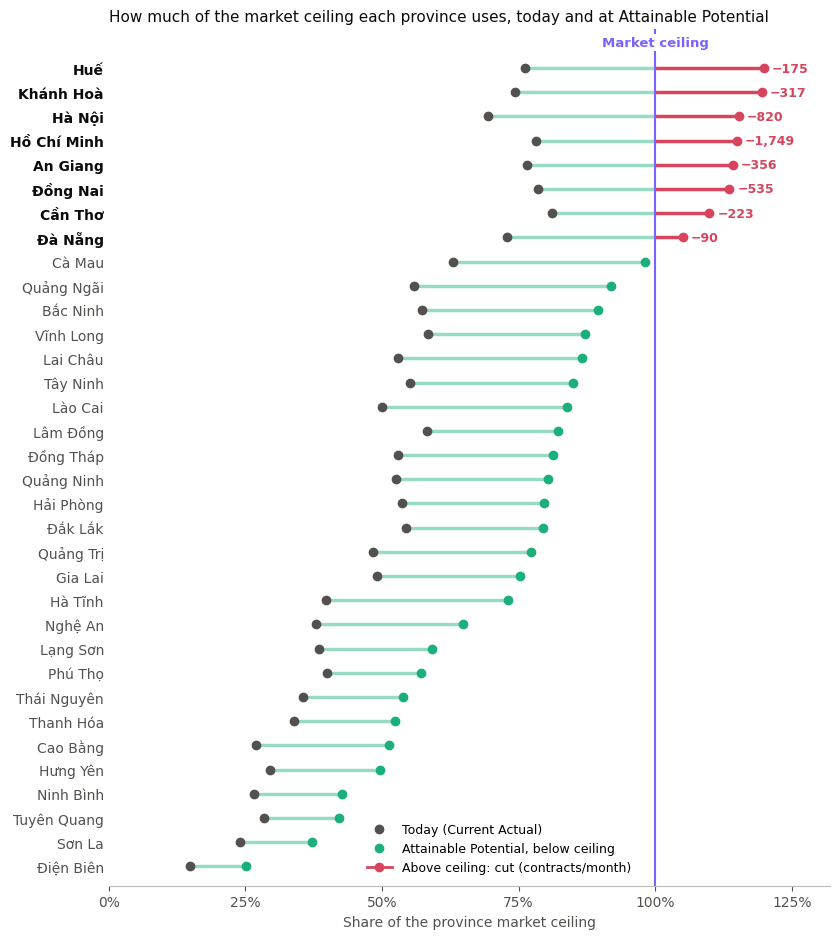

In [9]:
# Mỗi tỉnh: phần trăm trần thị trường đã dùng hôm nay (Current Actual) và khi đạt Attainable Potential trước trần
p = s.merge(tran[['pkey', 'province']], on='pkey').groupby('province').agg(
    so_shop=('skp_salesroom', 'size'), ca=('ca_hd_tong', 'sum'), ap_truoc_tran=('ap_tho', 'sum'), tran=('tran_shop', 'sum'), bi_cat=('tru_do_thi_truong', 'sum'))
p['ca_tren_tran'] = p.ca / p.tran
p['ap_truoc_tran_tren_tran'] = p.ap_truoc_tran / p.tran
p = p.sort_values('ap_truoc_tran_tren_tran', ascending=False)
cat = p[p.bi_cat > 0]; khong_cat = p[p.bi_cat == 0]
print(f"{len(cat)} tỉnh bị trần cắt: hôm nay đã dùng {cat.ca_tren_tran.min():.0%}–{cat.ca_tren_tran.max():.0%} trần")
print(f"{len(khong_cat)} tỉnh không bị cắt: hôm nay dùng {khong_cat.ca_tren_tran.min():.0%}–{khong_cat.ca_tren_tran.max():.0%} trần, "
      f"Attainable Potential trước trần tối đa {khong_cat.ap_truoc_tran_tren_tran.max():.0%} trần")
print('Tỉnh bị cắt, xếp theo phần trần đã dùng hôm nay: '
      + '; '.join(f"{t} {v:.0%}" for t, v in cat.ca_tren_tran.sort_values(ascending=False).items()))
ba_tinh = p.bi_cat.nlargest(3)
print(f"3 tỉnh bị cắt nhiều nhất: {', '.join(ba_tinh.index)}; giữ {ba_tinh.sum() / p.bi_cat.sum():.1%} phần bị cắt "
      f"({ba_tinh.sum():,.0f} trên {p.bi_cat.sum():,.0f} contract/tháng)")
print(f"3 tỉnh nhiều shop nhất: {', '.join(f'{t} ({n:,})' for t, n in p.so_shop.nlargest(3).items())}")

TIM, XANH, HONG = '#7b61ff', '#1baf7a', '#d6455d'
fig, ax = plt.subplots(figsize=(8.5, 9.5))
y = np.arange(len(p))[::-1]
for yi, (ten, r) in zip(y, p.iterrows()):
    dau, cuoi = r.ca_tren_tran, r.ap_truoc_tran_tren_tran
    ax.plot([dau, min(cuoi, 1)], [yi, yi], color=XANH, lw=2.5, alpha=0.45, solid_capstyle='butt')
    if cuoi > 1:
        ax.plot([1, cuoi], [yi, yi], color=HONG, lw=2.5, solid_capstyle='butt')
        ax.text(cuoi + 0.015, yi, f'−{r.bi_cat:,.0f}', va='center', color=HONG, fontsize=9, fontweight='bold')
    ax.plot(cuoi, yi, 'o', color=HONG if cuoi > 1 else XANH, ms=6)
    ax.plot(dau, yi, 'o', color=MUTED, ms=6)
ax.axvline(1, color=TIM, lw=1.5)
ax.text(1, len(p) - 0.2, 'Market ceiling', color=TIM, ha='center', va='bottom', fontsize=9.5, fontweight='bold',
        bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
ten_tinh = [t.replace('TP. ', '') for t in p.index]
ax.set_yticks(y); ax.set_yticklabels(ten_tinh)
for nhan, (ten, r) in zip(ax.get_yticklabels(), p.iterrows()):
    nhan.set_color(INK if r.bi_cat > 0 else MUTED); nhan.set_fontweight('bold' if r.bi_cat > 0 else 'normal')
ax.set_xlim(0, 1.32); ax.set_ylim(-0.8, len(p) + 0.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xticks([0, 0.25, 0.5, 0.75, 1, 1.25])
ax.set_xlabel('Share of the province market ceiling', color=MUTED)
ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=MUTED, label='Today (Current Actual)'),
                   Line2D([], [], marker='o', ls='', color=XANH, label='Attainable Potential, below ceiling'),
                   Line2D([], [], marker='o', ls='-', color=HONG, label='Above ceiling: cut (contracts/month)')],
          loc='lower right', bbox_to_anchor=(0.74, 0), frameon=False, fontsize=9)
ax.set_title('How much of the market ceiling each province uses, today and at Attainable Potential', loc='left', color=INK, fontsize=11)
plt.tight_layout(); luu_hinh(fig, 'b5_03_ceiling_by_province'); plt.show()

- 26 trên 34 tỉnh không bị trần cắt. Hôm nay các tỉnh này mới dùng 15–63% trần, và kể cả khi mọi shop đạt Attainable Potential thì vẫn dưới trần (cao nhất 98%). Ở các tỉnh này, thứ giới hạn shop là số SA và năng suất SA, không phải số người trong tỉnh.
- 8 tỉnh bị cắt hôm nay đã dùng 69–81% trần. TP. Cần Thơ dùng nhiều nhất (81%), không phải TP. Hồ Chí Minh (78%).
- TP. Hồ Chí Minh, TP. Hà Nội và Đồng Nai giữ 72,8% phần bị cắt (3.105 trên 4.266 contract mỗi tháng) vì đây là ba tỉnh có nhiều shop nhất, không phải vì gần trần nhất: TP. Hà Nội hôm nay mới dùng 69% trần, thấp nhất trong 8 tỉnh bị cắt.

## 5.4. Opportunity gap

Ô dưới đây tính opportunity gap theo funded volume:
- phần gap bán tại shop nhân với tiền vay trung bình mỗi contract của shop mà Bước 2 dùng cho BAU (`ticket_bau`);
- phần gap cross-sell nhân với tiền vay trung bình mỗi contract cross-sell của toàn mạng lưới trong BAU của Bước 2;
- funded volume của BAU lấy từ cột `bau_total_contribution_funded` của Bước 2.

Cột `so_voi_bau` chia mỗi dòng cho dòng BAU.

In [10]:
nb_ = bau.set_index('skp_salesroom')
ticket_xs = nb_.bau_xsell_funded_volume.sum() / nb_.bau_xsell_contracts.sum()
s['ticket_bau'] = s.skp_salesroom.map(nb_.ticket_bau).to_numpy()
s['bau_funded'] = s.skp_salesroom.map(nb_.bau_total_contribution_funded).to_numpy()
s['gap_funded'] = (s.gap - s.gap_xsell) * s.ticket_bau + s.gap_xsell * ticket_xs
s['ap_funded'] = s.bau_funded + s.gap_funded
print(f'Tiền vay trung bình mỗi contract cross-sell (Bước 2): {ticket_xs / 1e6:.1f} triệu đồng')
pd.DataFrame({'contract_moi_thang': [s.bau.sum(), s.ap.sum(), s.gap.sum()],
              'funded_ty_dong_moi_thang': [s.bau_funded.sum() / 1e9, s.ap_funded.sum() / 1e9, s.gap_funded.sum() / 1e9]},
             index=['BAU', 'Attainable Potential', 'Opportunity gap']).assign(
    so_voi_bau=lambda t: t.iloc[:, 0] / t.iloc[0, 0])

Tiền vay trung bình mỗi contract cross-sell (Bước 2): 12.7 triệu đồng


,contract_moi_thang,funded_ty_dong_moi_thang,so_voi_bau
BAU,"39,271.6",539.0,1
Attainable Potential,"55,595.3",761.9,1.416
Opportunity gap,"16,323.6",222.9,0.416


Nếu mọi shop làm tốt bằng 1/4 số shop cùng loại, trong giới hạn về rủi ro và trần thị trường, mạng lưới ký thêm 16.324 contract và 222,9 tỷ đồng tiền cho vay mỗi tháng so với khi để yên, tức cao hơn BAU 41,6% về số contract và 41,4% về tiền (222,9 / 539,0).

Ô dưới đây xem gap dồn vào bao nhiêu shop, và chia gap theo ngành hàng × cỡ shop.

In [11]:
g = s.gap.sort_values(ascending=False).to_numpy()
rows = [{'nhom_shop': f'{int(p * 100)}% shop có gap lớn nhất', 'so_shop': int(len(g) * p), 'ty_trong_gap': g[:int(len(g) * p)].sum() / g.sum(),
         'gap_nho_nhat_trong_nhom': g[int(len(g) * p) - 1]} for p in [0.05, 0.10, 0.25, 0.50]]
display(pd.DataFrame(rows))
print(f"Shop có gap = 0: {int((s.gap < 1e-9).sum()):,}; trong đó không có hồ sơ nào trong quý 3/2026: {int(((s.gap < 1e-9) & ~s.dang_ban).sum()):,}")
s.groupby(['salesroom_product', 'salesroom_category']).agg(so_shop=('skp_salesroom', 'size'), bau=('bau', 'sum'), gap=('gap', 'sum'),
    gap_trung_vi=('gap', 'median')).assign(gap_so_voi_bau=lambda t: t.gap / t.bau)

,nhom_shop,so_shop,ty_trong_gap,gap_nho_nhat_trong_nhom
0,5% shop có gap lớn nhất,587,0.299,4.613
1,10% shop có gap lớn nhất,1175,0.445,3.577
2,25% shop có gap lớn nhất,2938,0.743,2.152
3,50% shop có gap lớn nhất,5876,0.981,0.571


Shop có gap = 0: 4,896; trong đó không có hồ sơ nào trong quý 3/2026: 3,602


so_shop      bau     gap  gap_trung_vi  gap_so_voi_bau
salesroom_product salesroom_category                                                        
CD                Big                     451  4,190.0 1,799.8         0.723           0.430
                  Medium                 1858  7,439.0 2,842.0         0.891           0.382
                  Small                  3848 10,854.8 4,302.9         0.547           0.396
NS                Big                     439  1,483.8   669.4         0.071           0.451
                  Medium                 1643  4,299.7 1,719.3         0.132           0.400
                  Small                  1226  3,347.2 1,216.9         0.313           0.364
TW                Big                     390  1,600.0   838.5         1.389           0.524
                  Medium                  908  3,322.4 1,538.2         0.997           0.463
                  Small                   989  2,734.7 1,396.6         0.689           0.511

- Gap dồn vào một phần nhỏ số shop: 25% shop có gap lớn nhất (2.938 shop) giữ 74,3% tổng gap, mỗi shop trong nhóm này có gap từ 2,15 contract mỗi tháng trở lên. Một nửa số shop có gap nhỏ nhất chỉ giữ 1,9% (100% − 98,1%).
- 4.896 shop có gap bằng 0, trong đó 3.602 shop không có hồ sơ nào trong quý 3/2026. Với các shop không có hồ sơ, Bước 3 không đo được KPI nên không tính được mức tăng.
- So với BAU, shop TW có gap lớn nhất (46–52%), shop CD và NS 36–45%. Theo số tuyệt đối, shop CD Small có tổng gap lớn nhất (4.302,9 contract mỗi tháng) vì đây là nhóm đông nhất (3.848 shop).

## 5.5. Gap đến từ KPI nào

Gap của mỗi shop được chia thành các phần, giống Bước 3 mục 3.7:
- **giữ mức hiện tại**: nếu BAU thấp hơn Current Actual (Bước 2 dự báo shop đi xuống), phần chênh giữa hai số này là phần chỉ cần chặn đà giảm;
- **số SA, hồ sơ mỗi SA, tỷ lệ bị từ chối, tỷ lệ hủy**: phần tăng của bán trực tiếp, chia theo logarit của tỷ số "sau khi nâng / hiện tại" của từng KPI. Ví dụ số SA tăng gấp 2 và hồ sơ mỗi SA tăng gấp 1,5 thì số SA được chia phần lớn hơn (log 2 ≈ 0,69 so với log 1,5 ≈ 0,41);
- **cross-sell mỗi lead**: phần tăng của cross-sell.

Ở shop bị trần cắt, mọi phần được thu nhỏ theo cùng một tỷ lệ. Ô dưới đây cộng từng phần cho toàn mạng lưới.

,contract_moi_thang,ty_trong
giữ mức hiện tại (chặn đà giảm),"3,068.8",0.188
số SA,"5,246.5",0.321
hồ sơ mỗi SA,"6,963.7",0.427
tỷ lệ bị từ chối,62.204,0.004
tỷ lệ hủy,227.2,0.014
cross-sell mỗi lead,755.2,0.046


Kiểm tra: tổng các phần = 16,323.6; opportunity gap = 16,323.6


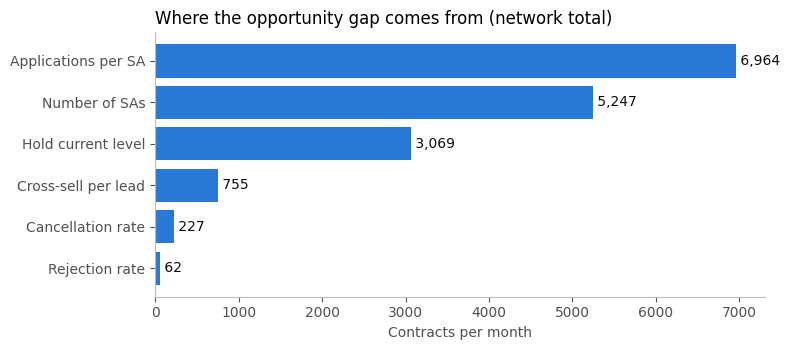

In [12]:
TEN_PHAN = {'giu_muc_hien_tai': 'giữ mức hiện tại (chặn đà giảm)', 'so_sa': 'số SA', 'ho_so_moi_sa': 'hồ sơ mỗi SA',
            'ty_le_tu_choi': 'tỷ lệ bị từ chối', 'ty_le_huy': 'tỷ lệ hủy', 'xsell': 'cross-sell mỗi lead'}
phan = pd.DataFrame({'contract_moi_thang': [s['gap_' + c].sum() for c in NHOM_PHAN]}, index=[TEN_PHAN[c] for c in NHOM_PHAN])
phan['ty_trong'] = phan.contract_moi_thang / s.gap.sum()
display(phan)
print(f"Kiểm tra: tổng các phần = {phan.contract_moi_thang.sum():,.1f}; opportunity gap = {s.gap.sum():,.1f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
p2 = phan.contract_moi_thang.sort_values()
EN = {'giữ mức hiện tại (chặn đà giảm)': 'Hold current level', 'số SA': 'Number of SAs', 'hồ sơ mỗi SA': 'Applications per SA',
      'tỷ lệ bị từ chối': 'Rejection rate', 'tỷ lệ hủy': 'Cancellation rate', 'cross-sell mỗi lead': 'Cross-sell per lead'}
ax.barh([EN[i] for i in p2.index], p2.to_numpy(), color=BLUE); ax.set_axisbelow(True)
for i, v_ in enumerate(p2.to_numpy()):
    ax.text(v_, i, f' {v_:,.0f}', va='center', color=INK)
ax.set_xlabel('Contracts per month'); ax.set_title('Where the opportunity gap comes from (network total)', loc='left')
plt.tight_layout(); luu_hinh(fig, 'b5_01_gap_sources'); plt.show()


Hai KPI về nhân viên chiếm phần lớn gap: hồ sơ mỗi SA 42,7% (6.963,7 contract mỗi tháng) và số SA 32,1% (5.246,5). Giữ mức hiện tại chiếm 18,8%. Cross-sell chỉ 4,6%, tỷ lệ hủy 1,4% và tỷ lệ bị từ chối 0,4%.


Bảng trên chia gap theo KPI. Câu lệnh dưới đây gộp các phần đó thành một **cầu nối từ BAU lên Attainable Potential**, xếp theo mức chắc chắn, từ đòn bẩy dễ làm và có bằng chứng nhất đến đòn bẩy cần kiểm chứng:
1. **Ký tốt hơn trên lượng khách đang có:** tỷ lệ bị từ chối, tỷ lệ hủy và cross-sell mỗi lead. Không cần thêm người hay thêm khách, chỉ cần sửa quy trình.
2. **Giữ mức hiện tại:** chặn đà giảm mà Bước 2 dự báo.
3. **Thêm SA:** cần chi phí nhân sự.
4. **Tăng hồ sơ mỗi SA:** cần thêm khách đến shop.

Câu lệnh cũng in hai con số để đánh giá bậc 3 và bậc 4:
- với bậc 3: số contract mỗi tháng được tính cho mỗi SA thêm, so với số contract mỗi SA đang làm được hiện nay;
- với bậc 4: trong các shop có hồ sơ mỗi SA thấp hơn mức 75% của peer group ở quý 1/2026, bao nhiêu phần trăm tự đạt mức đó vào quý 3/2026 mà không có can thiệp. Peer group ở đây là cỡ shop × ngành hàng × kiểu làm hồ sơ × tỉnh như Bước 3, chỉ lấy nhóm có từ 5 shop.

Biểu đồ vẽ cầu nối và được lưu thành `Bước 5/hinh/b5_02_bridge_bau_to_ap.png`.

,bac,contract_moi_thang,ty_trong_gap
0,BAU,"39,271.6",NaN
1,+ Ký tốt hơn trên khách hiện có,"1,044.6",0.064
2,+ Giữ mức hiện tại,"3,068.8",0.188
3,+ Thêm SA,"5,246.5",0.321
4,+ Tăng hồ sơ mỗi SA,"6,963.7",0.427
5,Attainable Potential sau trần,"55,595.3",NaN


Kiểm tra: BAU + 4 bậc = 55,595.3; Attainable Potential = 55,595.3
Bậc 3: 3,398 SA thêm ở 4,093 shop, mỗi SA thêm được tính 1.54 contract/tháng; hiện nay mỗi SA làm được 3.83 contract/tháng


Bậc 4: 2,904 shop dưới mức 75% của peer group ở quý 1/2026 và còn bán ở quý 3/2026; 14.6% tự đạt mức đó ở quý 3; shop đứng giữa có hồ sơ mỗi SA quý 3 / quý 1 = 1.00


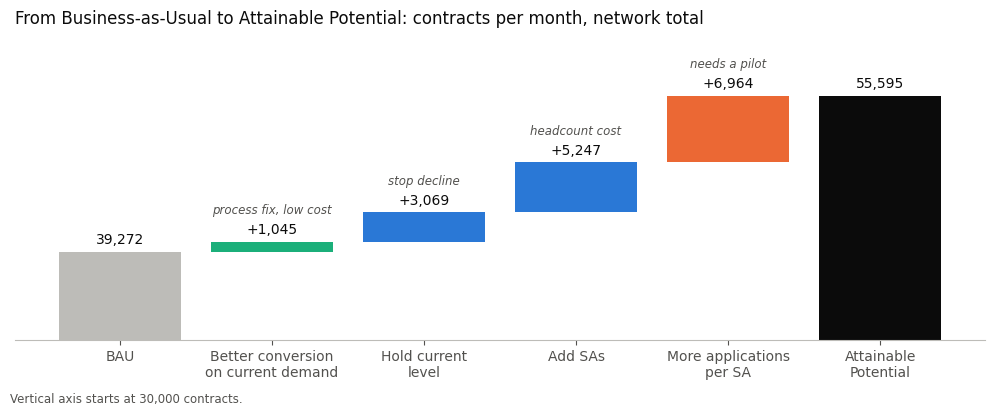

In [13]:
BAC = [('Ký tốt hơn trên khách hiện có', ['gap_ty_le_tu_choi', 'gap_ty_le_huy', 'gap_xsell']),
       ('Giữ mức hiện tại', ['gap_giu_muc_hien_tai']),
       ('Thêm SA', ['gap_so_sa']),
       ('Tăng hồ sơ mỗi SA', ['gap_ho_so_moi_sa'])]
cau_noi = pd.DataFrame([('BAU', s.bau.sum())] + [('+ ' + ten, s[cot].sum().sum()) for ten, cot in BAC]
                       + [('Attainable Potential sau trần', s.ap.sum())], columns=['bac', 'contract_moi_thang'])
cau_noi['ty_trong_gap'] = np.where(cau_noi.bac.str.startswith('+'), cau_noi.contract_moi_thang / s.gap.sum(), np.nan)
display(cau_noi)
print(f"Kiểm tra: BAU + 4 bậc = {cau_noi.contract_moi_thang.iloc[:5].sum():,.1f}; Attainable Potential = {s.ap.sum():,.1f}")

# Bậc 3: contract mỗi SA thêm (chỉ tính shop có phần gap do số SA), so với contract mỗi SA hiện nay
st_ = s[s.gap_so_sa > 1e-9]
them_sa = (st_.sau_so_sa - st_.ca_so_sa).sum()
print(f"Bậc 3: {them_sa:,.0f} SA thêm ở {len(st_):,} shop, mỗi SA thêm được tính {st_.gap_so_sa.sum() / them_sa:.2f} contract/tháng; "
      f"hiện nay mỗi SA làm được {s.ca_hd_truc_tiep.sum() / s.ca_so_sa.sum():.2f} contract/tháng")

# Bậc 4: shop dưới mức 75% hồ sơ mỗi SA của peer group ở quý 1/2026 có tự đạt mức đó ở quý 3/2026 không
sm_ = pd.read_csv(ROOT / 'Bước 1' / 'shop_month.csv', encoding='utf-8-sig')
def hs_moi_sa(tu, den):
    w = sm_[(sm_.thang >= tu) & (sm_.thang <= den)].groupby('skp_salesroom')[['ho_so', 'so_sa']].sum()
    return (w.ho_so / w.so_sa.where(w.so_sa > 0)).rename('hs_sa')
q1_ = s[['skp_salesroom'] + G].join(hs_moi_sa('2026-01-01', '2026-03-01'), on='skp_salesroom').dropna(subset=['hs_sa'])
q1_['n'] = q1_.groupby(G).hs_sa.transform('size'); q1_['p75'] = q1_.groupby(G).hs_sa.transform(lambda v: v.quantile(0.75))
duoi = q1_[(q1_.n >= 5) & (q1_.hs_sa < q1_.p75)].join(hs_moi_sa('2026-07-01', '2026-09-01').rename('hs_sa_q3'), on='skp_salesroom').dropna(subset=['hs_sa_q3'])
print(f"Bậc 4: {len(duoi):,} shop dưới mức 75% của peer group ở quý 1/2026 và còn bán ở quý 3/2026; "
      f"{(duoi.hs_sa_q3 >= duoi.p75).mean():.1%} tự đạt mức đó ở quý 3; shop đứng giữa có hồ sơ mỗi SA quý 3 / quý 1 = {(duoi.hs_sa_q3 / duoi.hs_sa).median():.2f}")

# Biểu đồ cầu nối (waterfall)
nhan = ['BAU', 'Better conversion\non current demand', 'Hold current\nlevel', 'Add SAs', 'More applications\nper SA', 'Attainable\nPotential']
chu_thich = ['', 'process fix, low cost', 'stop decline', 'headcount cost', 'needs a pilot', '']
gia_tri = cau_noi.contract_moi_thang.to_numpy()
mau = ['#bdbcb8', '#1baf7a', BLUE, BLUE, ORANGE, INK]
fig, ax = plt.subplots(figsize=(10, 4))
day = 0
for i, v_ in enumerate(gia_tri):
    if i in (0, len(gia_tri) - 1):
        ax.bar(i, v_, color=mau[i]); dinh = v_; day = v_ if i == 0 else day
    else:
        ax.bar(i, v_, bottom=day, color=mau[i]); dinh = day + v_; day = dinh
    ax.text(i, dinh + 500, (f'{v_:,.0f}' if i in (0, len(gia_tri) - 1) else f'+{v_:,.0f}'), ha='center', va='bottom', color=INK, fontsize=10)
    if chu_thich[i]:
        ax.text(i, dinh + 2600, chu_thich[i], ha='center', va='bottom', color=MUTED, fontsize=8.5, style='italic')
ax.set_xticks(range(len(nhan))); ax.set_xticklabels(nhan)
ax.set_ylim(30000, gia_tri[-1] * 1.12); ax.set_yticks([]); ax.spines['left'].set_visible(False)
ax.set_title('From Business-as-Usual to Attainable Potential: contracts per month, network total', loc='left', color=INK)
fig.text(0.01, -0.02, 'Vertical axis starts at 30,000 contracts.', color=MUTED, fontsize=8.5)
plt.tight_layout(); luu_hinh(fig, 'b5_02_bridge_bau_to_ap'); plt.show()


- Gap 16.324 contract mỗi tháng gồm bốn bậc có độ chắc chắn khác nhau. Bậc 1, ký tốt hơn trên khách hiện có, chỉ 1.044,6 contract (6,4% gap), nhưng không cần thêm người hay thêm khách nên làm được ngay.
- Bậc 2 và bậc 3 (giữ mức hiện tại 3.068,8 và thêm SA 5.246,5) cần nguồn lực. Ở bậc 3, mỗi SA thêm chỉ được tính 1,54 contract mỗi tháng, chưa bằng một nửa mức 3,83 contract mà một SA đang làm được hiện nay. Mức thấp này là do phần tăng đã bị giới hạn theo nhóm ở Bước 3 và bị trần thị trường cắt bớt ở mục trên.
- Bậc 4, tăng hồ sơ mỗi SA, lớn nhất (6.963,7 contract, 42,7% gap) nhưng kém chắc chắn nhất: trong 2.904 shop dưới mức 75% của peer group ở quý 1/2026, chỉ 14,6% tự đạt mức đó vào quý 3/2026, và shop đứng giữa giữ nguyên mức cũ. Phần này không tự đến; muốn đạt được phải có can thiệp, và cần thử trước trên một nhóm shop.

Bước 3 (mục 3.10) có một cách kiểm chứng: chỉ nâng tỷ lệ ký và cross-sell mỗi lead, giữ nguyên số hồ sơ và số lead, trên các shop đủ dữ liệu (file `Bước 3/shop_kiem_chung_ty_le.csv`). Câu lệnh dưới đây so trên đúng các shop đó: phần tăng theo cách kiểm chứng, bậc 1 của cầu nối (ký tốt hơn trên khách hiện có, sau trần thị trường), và tổng gap của các shop này.

In [14]:
kc = pd.read_csv(ROOT / 'Bước 3' / 'shop_kiem_chung_ty_le.csv', encoding='utf-8-sig')
chung = s.merge(kc[['skp_salesroom', 'tang_kiem_chung']], on='skp_salesroom')
pd.DataFrame({'so_shop': [len(chung)],
              'kiem_chung_chi_nang_ty_le': [chung.tang_kiem_chung.sum()],
              'bac_1_ky_tot_hon': [chung[['gap_ty_le_tu_choi', 'gap_ty_le_huy', 'gap_xsell']].sum().sum()],
              'tong_gap_cac_shop_nay': [chung.gap.sum()],
              'ty_trong_trong_gap_toan_mang': [chung.gap.sum() / s.gap.sum()]})

,so_shop,kiem_chung_chi_nang_ty_le,bac_1_ky_tot_hon,tong_gap_cac_shop_nay,ty_trong_trong_gap_toan_mang
0,1342,"1,355.7",326.7,"2,041.3",0.125


- Trên 1.342 shop đủ dữ liệu, cách kiểm chứng cho phần tăng nhờ ký tốt hơn là 1.355,7 contract mỗi tháng, gấp khoảng 4,1 lần bậc 1 của cầu nối ở cùng các shop (326,7). Bậc 1 nhỏ hơn vì giới hạn theo nhóm ở Bước 3 và trần thị trường ở mục 5.3 đã cắt phần tăng của các shop lớn này. Vì vậy bậc 1 (1.044,6 trên toàn mạng lưới) là con số thận trọng; mức có thể đạt được cao hơn.
- Các shop này giữ 12,5% tổng gap (2.041,3 contract mỗi tháng). 87,5% còn lại nằm ở shop nhỏ và shop mới, nơi không đủ hồ sơ để kiểm chứng theo cách này.

## 5.6. Sáu nhóm nguyên nhân

Mục này xét lần lượt các nhóm nguyên nhân: staffing (số nhân viên), execution (cách nhân viên làm việc), demand (nhu cầu của khách), merchant characteristics (đặc điểm của shop và đối tác), product mix (cơ cấu sản phẩm), risk (rủi ro), và các nguyên nhân khác dữ liệu cho thấy. Mỗi nhóm kết thúc bằng hành động tương ứng.

### 5.6.1. Staffing

Ô dưới đây lấy các shop có phần gap do số SA, cộng số SA cần thêm để mỗi shop đạt benchmark, và so số SA hiện tại với benchmark. Số SA của shop là số nhân viên khác nhau làm hồ sơ trong tháng, lấy trung bình 3 tháng, nên có thể là số lẻ: 0,667 nghĩa là shop có SA làm hồ sơ trong 2 trên 3 tháng của quý.

In [15]:
st = s[s.gap_so_sa > 1e-9]
print(f"Shop có phần gap do số SA: {len(st):,}; số SA cần thêm (cộng benchmark − hiện tại): {(st.sau_so_sa - st.ca_so_sa).sum():,.0f} SA")
pd.DataFrame({'so_sa_hien_tai': st.ca_so_sa.describe(percentiles=[.5]).loc[['50%', 'mean']],
              'so_sa_benchmark': st.sau_so_sa.describe(percentiles=[.5]).loc[['50%', 'mean']],
              'gap_do_so_sa_moi_shop': st.gap_so_sa.describe(percentiles=[.5]).loc[['50%', 'mean']]}).rename(index={'50%': 'trung vị', 'mean': 'trung bình'})

Shop có phần gap do số SA: 4,093; số SA cần thêm (cộng benchmark − hiện tại): 3,398 SA


,so_sa_hien_tai,so_sa_benchmark,gap_do_so_sa_moi_shop
trung vị,0.667,1.500,0.941
trung bình,0.752,1.582,1.282


- 4.093 shop có phần gap do thiếu SA; để các shop này đạt benchmark cần thêm khoảng 3.398 SA.
- Shop đứng giữa trong nhóm này chỉ có SA làm hồ sơ trong 2 trên 3 tháng của quý (0,667), trong khi benchmark là 1,5 SA. Nghĩa là có những tháng shop không có ai làm hồ sơ, nên tháng đó không bán được gì.
- Nhờ thêm SA, shop đứng giữa chỉ tăng được khoảng 0,94 contract mỗi tháng. Thêm SA tốn chi phí lương, nên chỉ đáng làm ở shop mà phần gap do số SA lớn.

**Hành động:** thêm SA, hoặc bố trí để shop có SA làm hồ sơ đều mọi tháng, ở shop có số SA thấp hơn benchmark; ưu tiên shop có phần gap do số SA lớn.

### 5.6.2. Execution

Execution gồm ba KPI: số hồ sơ mỗi SA làm được, tỷ lệ bị từ chối và tỷ lệ hủy. Ô dưới đây đếm số shop đang bán kém hơn benchmark ở từng KPI, mức trung vị của các shop đó và của benchmark, và phần gap do KPI này. Dòng cuối kiểm tra vì sao phần gap do tỷ lệ bị từ chối nhỏ.

In [16]:
ex = s[s.dang_ban]
rows = []
for cot, bm, ten, cao in [('ca_ho_so_moi_sa', 'bm_ho_so_moi_sa', 'hồ sơ mỗi SA', True), ('ca_ty_le_huy', 'bm_ty_le_huy', 'tỷ lệ hủy', False),
                          ('ca_ty_le_tu_choi', 'bm_ty_le_tu_choi', 'tỷ lệ bị từ chối', False)]:
    kem = (ex[cot] < ex[bm]) if cao else (ex[cot] > ex[bm])
    rows.append({'kpi': ten, 'so_shop_kem_benchmark': int(kem.sum()), 'shop_trung_vi': ex.loc[kem, cot].median(), 'benchmark_trung_vi': ex.loc[kem, bm].median(),
                 'gap_tu_kpi_nay': s['gap_' + {'hồ sơ mỗi SA': 'ho_so_moi_sa', 'tỷ lệ hủy': 'ty_le_huy', 'tỷ lệ bị từ chối': 'ty_le_tu_choi'}[ten]].sum()})
display(pd.DataFrame(rows))
kem_tc = ex.ca_ty_le_tu_choi > ex.bm_ty_le_tu_choi
print(f"Shop có tỷ lệ bị từ chối cao hơn benchmark: {int(kem_tc.sum()):,}; trong đó được phép giảm (đủ 30 contract tính rủi ro và "
      f"trễ hạn không cao hơn nhóm): {int((kem_tc & ex.duoc_giam_tu_choi).sum()):,}")

,kpi,so_shop_kem_benchmark,shop_trung_vi,benchmark_trung_vi,gap_tu_kpi_nay
0,hồ sơ mỗi SA,5934,2,4.667,"6,963.7"
1,tỷ lệ hủy,3502,0.123,0.027,227.2
2,tỷ lệ bị từ chối,4303,0.273,0.120,62.204


Shop có tỷ lệ bị từ chối cao hơn benchmark: 4,303; trong đó được phép giảm (đủ 30 contract tính rủi ro và trễ hạn không cao hơn nhóm): 653


- Hồ sơ mỗi SA là nguồn gap lớn nhất: 5.934 shop kém benchmark; ở các shop này, SA đứng giữa làm 2 hồ sơ mỗi tháng, trong khi benchmark là 4,667.
- 3.502 shop có tỷ lệ hủy cao hơn benchmark (12,3% so với 2,7% ở shop đứng giữa), nhưng phần gap chỉ 227,2 contract mỗi tháng, vì hồ sơ bị hủy chỉ là phần nhỏ của số hồ sơ, và chỉ shop có từ 10 hồ sơ mỗi quý mới được tính giảm.
- 4.303 shop có tỷ lệ bị từ chối cao hơn benchmark (27,3% so với 12,0%), nhưng chỉ 653 shop được phép giảm, vì phải có đủ 30 contract để đo rủi ro và khách không trễ hạn nhiều hơn mức chung của peer group. Vì vậy phần gap do tỷ lệ bị từ chối chỉ 62 contract mỗi tháng.

**Hành động:** đào tạo và kèm cặp SA để mỗi SA làm nhiều hồ sơ hơn; gọi lại khách đã được duyệt nhưng chưa ký để giảm hồ sơ bị hủy. Không nới việc duyệt hồ sơ ở shop có khách trả nợ kém hoặc chưa đủ contract để biết.

### 5.6.3. Demand

Demand (nhu cầu) của shop có hai nguồn: khách đến shop, giới hạn bởi dân số quanh shop; và lead, tức khách cũ được công ty mời vay thêm. Phần dân số đã thấy ở mục 5.3: 4.264 contract mỗi tháng bị trần thị trường cắt ở 8 tỉnh. Ô dưới đây xét phần lead: chia shop đang bán theo số lead mỗi tháng, rồi so cross-sell và gap. Cột `xsell_moi_lead` là trung vị số contract cross-sell trên mỗi lead.

In [17]:
ld = s[s.dang_ban].copy()
ld['nhom_lead'] = pd.cut(ld.ca_lead, [-0.1, 0, 5, 20, np.inf], labels=['0 lead', '1–5 lead', '5–20 lead', 'trên 20 lead'])
ld.groupby('nhom_lead', observed=True).agg(so_shop=('skp_salesroom', 'size'), lead_tb=('ca_lead', 'mean'), xsell_tb=('ca_xsell', 'mean'),
    xsell_moi_lead=('ca_xsell_moi_lead', 'median'), gap_xsell=('gap_xsell', 'sum'), gap=('gap', 'sum'))

,so_shop,lead_tb,xsell_tb,xsell_moi_lead,gap_xsell,gap
nhom_lead,,,,,,
0 lead,756,0,0,NaN,0,"1,365.3"
1–5 lead,4940,1.993,0.082,0,235.1,"10,326.6"
5–20 lead,1898,9.892,0.365,0.017,282.8,"2,833.0"
trên 20 lead,497,47.488,1.307,0.021,237.4,"1,776.3"


- 4.940 trên 8.091 shop đang bán chỉ có 1–5 lead mỗi tháng (trung bình 2), và 756 shop không có lead nào. Shop đứng giữa trong nhóm 1–5 lead không có contract cross-sell nào.
- Ngay cả ở shop có nhiều lead, mỗi lead chỉ tạo khoảng 0,02 contract cross-sell (0,017 ở nhóm 5–20 lead, 0,021 ở nhóm trên 20 lead), tức cần khoảng 50 lead mới ra một contract. Phần gap do cross-sell của cả mạng lưới chỉ 755,2 contract mỗi tháng.
- Vì vậy thiếu lead không phải là lý do chính khiến shop bán ít. Giới hạn về demand rõ nhất nằm ở các tỉnh đã chạm trần (mục 5.3) và ở tỷ lệ chốt lead rất thấp.

**Hành động:** ở các tỉnh đã chạm trần, không thêm nguồn lực bán vì thị trường không còn chỗ; giao thêm lead chỉ có ích khi đi kèm đào tạo SA cách chào Credit Card và Cash Loan cho khách cũ.

### 5.6.4. Merchant characteristics

Ô dưới đây so gap giữa các nhóm shop đang bán theo 4 đặc điểm: cỡ shop, kiểu làm hồ sơ (Aldi: nhân viên của cửa hàng tự làm hồ sơ; Non-Aldi: SA của công ty làm hồ sơ), loại đối tác (`seller_type` trong bảng seller), và shop mới (`shop_moi` = 1: hoạt động dưới 6 tháng). Cột `shop_gap_tu_2` là tỷ lệ shop có gap từ 2 contract mỗi tháng trở lên.

In [18]:
m = sr[['skp_salesroom', 'skp_seller']].merge(seller[['skp_seller', 'seller_type']], on='skp_seller', how='left')
s['seller_type'] = s.skp_salesroom.map(m.set_index('skp_salesroom').seller_type).fillna('không có trong bảng seller').to_numpy()
def theo(cot):
    t = s[s.dang_ban].groupby(cot).agg(so_shop=('skp_salesroom', 'size'), ca_trung_vi=('ca_hd_tong', 'median'), bau=('bau', 'sum'), gap=('gap', 'sum'),
                                       shop_gap_tu_2=('gap', lambda v: (v >= 2).mean()))
    t['gap_so_voi_bau'] = t.gap / t.bau
    return t
for cot in ['salesroom_category', 'salesroom_model', 'seller_type', 'shop_moi']:
    display(theo(cot))

,so_shop,ca_trung_vi,bau,gap,shop_gap_tu_2,gap_so_voi_bau
salesroom_category,,,,,,
Big,896,2.667,"7,233.7","3,304.3",0.501,0.457
Medium,2986,2,"14,883.7","6,091.6",0.453,0.409
Small,4209,1.667,"16,648.3","6,905.2",0.329,0.415


,so_shop,ca_trung_vi,bau,gap,shop_gap_tu_2,gap_so_voi_bau
salesroom_model,,,,,,
Aldi,2142,2,"11,707.7","5,189.8",0.369,0.443
Non-Aldi,5949,2,"27,058.1","11,111.3",0.402,0.411


,so_shop,ca_trung_vi,bau,gap,shop_gap_tu_2,gap_so_voi_bau
seller_type,,,,,,
Key Account,142,11.500,"3,948.4","1,794.1",0.514,0.454
Local Partner,164,4.833,"2,413.7",280.3,0.341,0.116
NS KA,797,2,"3,559.5","1,345.3",0.358,0.378
Stone Shop,6799,1.667,"26,952.2","12,539.3",0.396,0.465
TW Key Dealer,189,6.667,"1,891.9",342.2,0.407,0.181


,so_shop,ca_trung_vi,bau,gap,shop_gap_tu_2,gap_so_voi_bau
shop_moi,,,,,,
0,5665,2,"29,106.9","10,669.8",0.366,0.367
1,2426,1.333,"9,658.9","5,631.4",0.459,0.583


- Cỡ shop: gap so với BAU gần như bằng nhau ở 3 cỡ (41–46%). Cỡ shop không tạo ra hay kìm gap, vì Bước 3 đã so mỗi shop với các shop cùng cỡ.
- Kiểu làm hồ sơ: Aldi 44% và Non-Aldi 41%, cũng gần nhau.
- Loại đối tác: shop của Local Partner và TW Key Dealer có gap thấp hẳn (11,6% và 18,1% BAU). Các shop này bán nhiều hơn (trung vị 4,8 và 6,7 contract mỗi tháng, so với 1,7 của Stone Shop) và đã gần mức của shop tốt cùng loại. Stone Shop chiếm 6.799 trên 8.091 shop đang bán và có gap 46,5% BAU.
- Shop mới có gap 58,3% BAU, so với 36,7% ở shop đã hoạt động từ 6 tháng. Shop mới bán ít hơn (trung vị 1,3 so với 2 contract mỗi tháng), và Bước 2 dự báo shop mới giảm dần sau đỉnh của những tháng đầu.

**Hành động:** với shop mới, ASM (Area Sales Manager – quản lý bán hàng khu vực) theo sát 6 tháng đầu để giữ doanh số; với shop của đối tác đã gần mức tốt nhất (Local Partner, TW Key Dealer), không cần thêm nguồn lực.

### 5.6.5. Product mix

Ô dưới đây chia shop đang bán theo cơ cấu nhóm hàng trong quý 3/2026 (chỉ một nhóm hàng, hoặc từ hai nhóm hàng trở lên), trong từng mức doanh số, vì shop bán ít thì tự nhiên chỉ có một nhóm hàng. Dòng cuối đếm số shop không có contract cross-sell nào.

In [19]:
q3 = mix.groupby('skp_salesroom').hd_ky.agg(['sum', 'max'])
s['ty_trong_nhom_hang_lon_nhat'] = s.skp_salesroom.map(q3['max'] / q3['sum']).to_numpy()
pm = s[s.dang_ban & s.ty_trong_nhom_hang_lon_nhat.notna()].copy()
pm['quy_mo'] = pd.cut(pm.ca_hd_truc_tiep, [0, 3, 10, np.inf], labels=['dưới 3 contract', '3–10 contract', 'từ 10 contract'], include_lowest=True)
pm['co_cau'] = np.where(pm.ty_trong_nhom_hang_lon_nhat >= 0.999, 'chỉ một nhóm hàng', 'từ hai nhóm hàng')
display(pm.groupby(['quy_mo', 'co_cau'], observed=True).agg(so_shop=('skp_salesroom', 'size'), so_sa=('ca_so_sa', 'median'),
    ho_so_moi_sa=('ca_ho_so_moi_sa', 'median'), bau=('bau', 'sum'), gap=('gap', 'sum')).assign(gap_so_voi_bau=lambda t: t.gap / t.bau))
print(f"Shop đang bán không có contract cross-sell nào trong quý 3/2026: {int((s.dang_ban & (s.ca_xsell == 0)).sum()):,} trên {int(s.dang_ban.sum()):,}")

so_shop  so_sa  ho_so_moi_sa      bau     gap  gap_so_voi_bau
quy_mo          co_cau                                                                          
dưới 3 contract chỉ một nhóm hàng     3620  0.667         1.500  4,590.7 8,625.3           1.879
                từ hai nhóm hàng      1226      1         2.250  2,330.2 2,757.8           1.184
3–10 contract   chỉ một nhóm hàng      734  1.333             5  3,895.4   786.7           0.202
                từ hai nhóm hàng      1182  1.333         4.800  7,057.3 1,649.3           0.234
từ 10 contract  chỉ một nhóm hàng      231  2.667        10.714  4,600.6   435.3           0.095
                từ hai nhóm hàng       664      2            11 15,958.1 2,036.2           0.128

Shop đang bán không có contract cross-sell nào trong quý 3/2026: 5,808 trên 8,091


- Ở cùng mức doanh số, shop chỉ bán một nhóm hàng không có gap lớn hơn shop bán nhiều nhóm: ở mức 3–10 contract là 20,2% so với 23,4% BAU, ở mức từ 10 contract là 9,5% so với 12,8%. Số hồ sơ mỗi SA cũng gần như bằng nhau (5 so với 4,8; 10,7 so với 11).
- Chỉ ở mức dưới 3 contract, shop một nhóm hàng có gap cao hơn (188% so với 118% BAU), nhưng các shop này cũng có ít SA hơn (0,667 so với 1) và mỗi SA làm ít hồ sơ hơn (1,5 so với 2,25), tức chênh lệch đến từ nhân viên.
- 5.808 trên 8.091 shop đang bán không có contract cross-sell nào trong quý 3/2026.
- Kết luận: cơ cấu nhóm hàng không phải nguyên nhân của gap. Phần product mix có ảnh hưởng là việc bán thêm Cash Loan và Credit Card cho khách cũ, đã nằm trong phần cross-sell (4,6% gap).

**Hành động:** không cần đổi cơ cấu nhóm hàng của shop; phần cross-sell xử lý như ở mục 5.6.3.

### 5.6.6. Risk

Shop có khách trả nợ kém thì không nên đẩy bán thêm. Ô dưới đây gắn nhãn **rủi ro cao** cho shop có tỷ lệ contract trễ hạn trong 4 kỳ đầu cao hơn peer group một cách chắc chắn. Cách kiểm tra là binomial test (kiểm định nhị thức): giả sử khách của shop trả nợ giống khách của peer group, tính xác suất để shop có từng ấy contract trễ hạn trở lên; nếu xác suất dưới 5% thì coi chênh lệch là thật, không do may rủi. Chỉ xét shop có từ 10 contract tính rủi ro, vì với ít hơn, chỉ một contract trễ hạn đã làm tỷ lệ của shop đổi từ 10 điểm phần trăm trở lên.

In [20]:
from scipy import stats
tre = (s.rr_hd * s.rr_ty_le_tre.fillna(0)).round()
s['p_rui_ro'] = np.where(s.rr_hd > 0, stats.binom.sf(tre - 1, s.rr_hd.astype(int), s.rr_peer_group.fillna(0)), 1.0)
s['rui_ro_cao'] = (s.rr_hd >= 10) & (s.rr_ty_le_tre > s.rr_peer_group) & (s.p_rui_ro < 0.05)
r = s[s.rui_ro_cao]
print(f"Shop rủi ro cao: {len(r):,}; tỷ lệ trễ hạn trung vị {r.rr_ty_le_tre.median():.1%} so với {r.rr_peer_group.median():.1%} của peer group; "
      f"Current Actual {r.ca_hd_tong.sum():,.0f}, opportunity gap {r.gap.sum():,.0f} contract/tháng")
print(f"Toàn bộ shop có contract tính rủi ro: {int((s.rr_hd > 0).sum()):,}; có từ 10 contract: {int((s.rr_hd >= 10).sum()):,}")
r[['rr_hd', 'rr_ty_le_tre', 'rr_peer_group', 'ca_hd_tong', 'gap']].describe(percentiles=[.5]).loc[['count', 'mean', '50%']]

Shop rủi ro cao: 379; tỷ lệ trễ hạn trung vị 48.9% so với 27.7% của peer group; Current Actual 2,957, opportunity gap 449 contract/tháng
Toàn bộ shop có contract tính rủi ro: 6,696; có từ 10 contract: 3,565


,rr_hd,rr_ty_le_tre,rr_peer_group,ca_hd_tong,gap
count,379,379,379,379,379
mean,67.153,0.503,0.296,7.801,1.184
50%,40,0.489,0.277,4,0.664


- 379 shop có rủi ro cao. Ở shop đứng giữa, 48,9% contract có khách trễ hạn trong 4 kỳ đầu, so với 27,7% của peer group.
- Các shop này đang ký 2.957 contract mỗi tháng và có gap 449 contract mỗi tháng. Phần gap này không nên khai thác.
- Chỉ 3.565 trên 6.696 shop có contract tính rủi ro có từ 10 contract, nên với gần một nửa số shop, rủi ro chưa đo được chắc chắn.

**Hành động:** không thêm nguồn lực bán cho shop rủi ro cao; bộ phận rủi ro rà soát hồ sơ và SA của các shop này.

### 5.6.7. Nguyên nhân khác

Ô dưới đây đếm hai nhóm shop không thuộc 6 nhóm trên: shop đang đi xuống (BAU thấp hơn Current Actual) và shop không có hồ sơ nào trong quý 3/2026.

In [21]:
giam = s[s.gap_giu_muc_hien_tai > 1e-9]
print(f"Shop có BAU thấp hơn Current Actual (đang đi xuống): {len(giam):,}; phần gap chỉ để giữ mức hiện tại: {giam.gap_giu_muc_hien_tai.sum():,.0f} contract/tháng")
print(f"Shop không có hồ sơ nào trong quý 3/2026: {int((~s.dang_ban).sum()):,}; BAU của các shop này: {s.loc[~s.dang_ban, 'bau'].sum():,.0f} contract/tháng")

Shop có BAU thấp hơn Current Actual (đang đi xuống): 4,426; phần gap chỉ để giữ mức hiện tại: 3,069 contract/tháng
Shop không có hồ sơ nào trong quý 3/2026: 3,661; BAU của các shop này: 506 contract/tháng


- 4.426 shop được Bước 2 dự báo sẽ bán ít hơn hiện tại; phần gap chỉ để giữ mức hiện tại là 3.069 contract mỗi tháng. Nguyên nhân ở đây là đà giảm của shop, không phải một KPI cụ thể.
- 3.661 shop không có hồ sơ nào trong quý 3/2026; BAU của các shop này cộng lại chỉ 506 contract mỗi tháng. Với các shop này, câu hỏi là có tiếp tục duy trì shop hay không.

**Hành động:** với shop đang đi xuống, ASM vào shop tìm lý do và giữ lại SA, nguồn khách; với shop không hoạt động, xem lại việc duy trì shop.

## 5.7. Nguyên nhân chính và hành động cho từng shop

Mỗi shop được gắn một nguyên nhân chính là phần lớn nhất trong gap của shop (mục 5.5), với hai ngoại lệ:
- shop rủi ro cao (mục 5.6.6) được ghi nguyên nhân Risk, vì không nên đẩy bán thêm dù gap lớn;
- shop có hơn một nửa phần tăng bị trần thị trường cắt được ghi "Demand – thị trường gần trần".

Ô dưới đây đếm số shop, gap và hành động theo từng nguyên nhân chính.

In [22]:
NGUYEN_NHAN = {'giu_muc_hien_tai': 'Đà giảm của shop', 'so_sa': 'Staffing', 'ho_so_moi_sa': 'Execution – năng suất SA',
               'ty_le_huy': 'Execution – hồ sơ bị hủy', 'ty_le_tu_choi': 'Execution – hồ sơ bị từ chối', 'xsell': 'Demand – chốt lead cross-sell'}
HANH_DONG = {'Đà giảm của shop': 'ASM vào shop tìm lý do doanh số giảm (mất SA, chủ shop đổi ưu tiên, đối thủ), giữ lại SA và nguồn khách',
             'Staffing': 'Thêm SA cho shop đến mức benchmark của peer group',
             'Execution – năng suất SA': 'Đào tạo và kèm cặp SA để mỗi SA làm được nhiều hồ sơ hơn',
             'Execution – hồ sơ bị hủy': 'Gọi lại khách có hồ sơ đã duyệt nhưng chưa ký, rút ngắn thời gian từ duyệt đến ký',
             'Execution – hồ sơ bị từ chối': 'Hướng dẫn SA chọn đúng khách và nộp hồ sơ đủ giấy tờ (chỉ ở shop khách trả nợ tốt)',
             'Demand – chốt lead cross-sell': 'Đào tạo cách chào Credit Card và Cash Loan cho khách cũ, giao thêm lead',
             'Risk': 'Không đẩy bán thêm; rà soát chất lượng hồ sơ cùng bộ phận rủi ro',
             'Demand – thị trường gần trần': 'Không thêm nguồn lực bán; tỉnh đã gần mức thâm nhập cao nhất',
             'Không có gap': 'Giữ nguyên'}
pc = ['gap_' + c for c in NHOM_PHAN]
s['nguyen_nhan_chinh'] = np.where(s.gap > 1e-9, s[pc].idxmax(axis=1).str.replace('gap_', '').map(NGUYEN_NHAN), 'Không có gap')
s.loc[(s.tru_do_thi_truong > 0.5 * s.gap_truoc_tran) & (s.gap_truoc_tran > 1e-9), 'nguyen_nhan_chinh'] = 'Demand – thị trường gần trần'
s.loc[s.rui_ro_cao, 'nguyen_nhan_chinh'] = 'Risk'
s['hanh_dong'] = s.nguyen_nhan_chinh.map(HANH_DONG)
t = s.groupby('nguyen_nhan_chinh').agg(so_shop=('skp_salesroom', 'size'), gap=('gap', 'sum'), gap_funded_ty=('gap_funded', lambda v: v.sum() / 1e9))
t['ty_trong_gap'] = t.gap / t.gap.sum()
t = t.sort_values('gap', ascending=False)
t['hanh_dong'] = t.index.map(HANH_DONG)
t

,so_shop,gap,gap_funded_ty,ty_trong_gap,hanh_dong
nguyen_nhan_chinh,,,,,
Execution – năng suất SA,2663,"7,908.1",105.9,0.484,Đào tạo và kèm cặp SA để mỗi SA làm được nhiều hồ sơ hơn
Staffing,1469,"4,561.1",63.461,0.279,Thêm SA cho shop đến mức benchmark của peer group
Đà giảm của shop,1502,"2,527.2",35.657,0.155,"ASM vào shop tìm lý do doanh số giảm (mất SA, chủ shop đổi ưu tiên, đối thủ), giữ lại SA và nguồn khách"
Demand – thị trường gần trần,825,564.4,7.755,0.035,Không thêm nguồn lực bán; tỉnh đã gần mức thâm nhập cao nhất
Risk,379,448.7,6.236,0.027,Không đẩy bán thêm; rà soát chất lượng hồ sơ cùng bộ phận rủi ro
Demand – chốt lead cross-sell,253,229.0,3.018,0.014,"Đào tạo cách chào Credit Card và Cash Loan cho khách cũ, giao thêm lead"
Execution – hồ sơ bị hủy,39,61.010,0.664,0.004,"Gọi lại khách có hồ sơ đã duyệt nhưng chưa ký, rút ngắn thời gian từ duyệt đến ký"
Execution – hồ sơ bị từ chối,14,24.117,0.263,0.001,Hướng dẫn SA chọn đúng khách và nộp hồ sơ đủ giấy tờ (chỉ ở shop khách trả nợ tốt)
Không có gap,4608,0,0,0,Giữ nguyên


- Execution – năng suất SA là nguyên nhân chính của 2.663 shop, giữ 48,4% tổng gap (7.908,1 contract và 105,9 tỷ đồng mỗi tháng).
- Staffing đứng thứ hai: 1.469 shop, 27,9% gap.
- Đà giảm của shop: 1.502 shop, 15,5% gap.
- Các nguyên nhân còn lại cộng lại chỉ 8,1% gap: thị trường gần trần (825 shop), rủi ro (379 shop), cross-sell (253 shop), hồ sơ bị hủy (39 shop), hồ sơ bị từ chối (14 shop).
- 4.608 shop không có gap.

## 5.8. Hai shop cùng doanh số, gap khác nhau

Ô dưới đây tìm hai shop có thật, cùng tỉnh, cùng ngành hàng, cùng kiểu làm hồ sơ và cùng Current Actual. Để kết quả đáng tin, cả hai shop phải đã hoạt động từ 12 tháng, có peer group từ 20 shop, không rủi ro cao và không bị trần thị trường cắt. Shop thứ nhất không còn chỗ tăng nhờ KPI (Attainable Potential trước khi áp trần không cao hơn BAU). Shop thứ hai có nguyên nhân chính là staffing hoặc execution; chọn shop có gap lớn nhất. Cột `bm_hd_truc_tiep` là số contract bán trực tiếp mà 1/4 số shop tốt nhất cùng peer group đạt được.

In [23]:
c = s[s.dang_ban & (s.so_thang >= 12) & (s.so_shop_peer_group >= 20) & ~s.rui_ro_cao & (s.tru_do_thi_truong < 1e-9) & (s.ca_hd_tong >= 4)]
A_ = c[(c.gap_truoc_tran < 1e-9)]                                                   # đã bằng hoặc hơn benchmark ở mọi KPI
B_ = c[c.nguyen_nhan_chinh.isin(['Staffing', 'Execution – năng suất SA'])]
cap = A_.merge(B_, on=['salesroom_province', 'salesroom_product', 'salesroom_model', 'ca_hd_tong'], suffixes=('_a', '_b'))
A, B = cap.loc[cap.gap_b.idxmax(), ['skp_salesroom_a', 'skp_salesroom_b']].astype(int)
COT = ['skp_salesroom', 'salesroom_category', 'salesroom_product', 'salesroom_model', 'salesroom_province', 'so_thang',
       'ca_hd_tong', 'bau', 'ap', 'tran_shop', 'gap', 'gap_funded', 'bm_hd_truc_tiep',
       'ca_so_sa', 'bm_so_sa', 'ca_ho_so_moi_sa', 'bm_ho_so_moi_sa', 'ca_ty_le_tu_choi', 'bm_ty_le_tu_choi', 'ca_ty_le_huy', 'bm_ty_le_huy',
       'ca_lead', 'ca_xsell', 'rr_ty_le_tre', 'rr_peer_group', 'nguyen_nhan_chinh'] + pc
s.set_index('skp_salesroom').loc[[A, B]].reset_index()[COT].T

,0,1
skp_salesroom,90118566,102169356
salesroom_category,Small,Medium
salesroom_product,CD,CD
salesroom_model,Non-Aldi,Non-Aldi
salesroom_province,Đắk Lắk,Đắk Lắk
so_thang,21,17
ca_hd_tong,4.333,4.333
bau,4.924,3.597
ap,4.924,6.524
tran_shop,6.189,8.200


Shop 90118566 và shop 102169356 cùng ở Đắk Lắk, cùng bán điện thoại, điện máy (CD), cùng kiểu Non-Aldi và cùng ký 4,33 contract mỗi tháng trong quý 3/2026. Nhưng:
- Shop 90118566 là shop Small. 1/4 số shop Small tốt nhất cùng loại ở Đắk Lắk ký 3,67 contract bán trực tiếp mỗi tháng, và shop này đã ký nhiều hơn mức đó. BAU của shop là 4,92 contract mỗi tháng. Nâng KPI không đưa shop lên cao hơn mức của shop tốt cùng loại, nên gap bằng 0.
- Shop 102169356 là shop Medium. 1/4 số shop Medium tốt nhất ký 6,33 contract. Shop có 1,67 SA nhưng mỗi SA chỉ làm 2,8 hồ sơ mỗi tháng, so với 5,16 của benchmark. BAU của shop chỉ 3,60 (Bước 2 dự báo giảm). Attainable Potential là 6,52, gap là 2,93 contract và khoảng 29 triệu đồng mỗi tháng: 1,98 contract nhờ nâng hồ sơ mỗi SA, 0,74 nhờ giữ mức hiện tại, 0,19 nhờ cross-sell và 0,02 nhờ giảm tỷ lệ bị từ chối.
- Vì vậy, dù hai shop đang bán bằng nhau, chỉ shop 102169356 đáng được đầu tư thêm, và việc cần làm là đào tạo để SA làm nhiều hồ sơ hơn. Shop 90118566 đã bán hơn 3/4 số shop cùng cỡ; muốn tăng nữa thì cần thay đổi lớn hơn, như nâng cỡ shop, không nằm trong các can thiệp thông thường.

## 5.9. Ghi kết quả

In [24]:
out = s[['skp_salesroom'] + G + ['shop_moi', 'so_thang', 'dang_ban', 'so_shop_peer_group', 'dung_bm_toan_quoc', 'seller_type', 'pkey',
         'ca_hd_truc_tiep', 'ca_xsell', 'ca_hd_tong', 'ca_so_sa', 'ca_ho_so_moi_sa', 'ca_ty_le_ky', 'ca_ty_le_huy', 'ca_lead',
         'bau', 'bau_funded', 'ticket_bau', 'ap_truoc_bau', 'ap_tho', 'ap', 'ap_funded', 'tran_tinh_thang', 'tran_shop',
         'gap', 'gap_funded', 'gap_truoc_tran', 'tru_do_thi_truong'] + pc +
        ['sau_so_sa', 'rr_hd', 'rr_ty_le_tre', 'rr_peer_group', 'p_rui_ro', 'rui_ro_cao', 'nguyen_nhan_chinh', 'hanh_dong']]
out.to_csv(ROOT / 'Bước 5' / 'shop_gap.csv', index=False, encoding='utf-8-sig')
tran.to_csv(ROOT / 'Bước 5' / 'province_ceiling_q3.csv', index=False, encoding='utf-8-sig')
print(f"Đã ghi Bước 5/shop_gap.csv: {len(out):,} dòng; Bước 5/province_ceiling_q3.csv: {len(tran)} tỉnh")

Đã ghi Bước 5/shop_gap.csv: 11,752 dòng; Bước 5/province_ceiling_q3.csv: 34 tỉnh


## 5.10. Tóm tắt

- Bốn con số được ghép từ Bước 1 đến Bước 4 cho 11.752 shop. Trần của Bước 4 được tính lại trên cùng quý 3/2026 và chia theo mức thực tế của shop, để không shop nào có trần thấp hơn mức đang bán.
- Opportunity gap của toàn mạng lưới là 16.324 contract và 222,9 tỷ đồng mỗi tháng, bằng 41,6% BAU. 25% shop có gap lớn nhất giữ 74,3% tổng gap.
- Gap chủ yếu đến từ nhân viên: hồ sơ mỗi SA 42,7%, số SA 32,1%; giữ mức hiện tại 18,8%. Cross-sell, tỷ lệ hủy và tỷ lệ bị từ chối cộng lại 6,4%.
- Xếp theo mức chắc chắn, gap gồm bốn bậc: ký tốt hơn trên khách hiện có 1.044,6 (làm được ngay), giữ mức hiện tại 3.068,8 và thêm SA 5.246,5 (cần nguồn lực), tăng hồ sơ mỗi SA 6.963,7 (cần thử trước). Cách kiểm chứng ở Bước 3 (chỉ nâng tỷ lệ, giữ nguyên số hồ sơ) cho 1.355,7 contract mỗi tháng trên 1.342 shop đủ dữ liệu, gấp 4,1 lần bậc 1 ở cùng các shop, nên bậc 1 là con số thận trọng.
- Trần thị trường cắt 20,7% phần tăng, ở 8 tỉnh; 26 tỉnh còn lại vẫn dưới trần kể cả khi mọi shop đạt Attainable Potential. TP. Hồ Chí Minh, TP. Hà Nội và Đồng Nai giữ 72,8% phần bị cắt vì có nhiều shop nhất. Cỡ shop, kiểu làm hồ sơ và cơ cấu nhóm hàng không giải thích được gap. 379 shop rủi ro cao không nên được đẩy bán thêm.
- Câu hỏi tiếp theo: khi nguồn lực có hạn, nên dồn vào shop nào trước. Bước 6 dùng file `Bước 5/shop_gap.csv` để chia shop thành các nhóm ưu tiên.